# Tarea 29

Objetivo: Realizar un análisis de descomposición  de valores singulares a una base de datos de manera que puedas generar conclusiones de agrupación de acuerdo a diversas categorías.

### Carga de librerias y dataset

In [15]:
# Load libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt



In [16]:
# Set the data
df = pd.DataFrame(np.array([[7,6.5,9.2, 8.6,8], [7.5,9.4,7.3,7,7], [7.6,9.2,8,8,7.5], 
                            [5,6.5,6.5,7,9], [6,6,7.8,8.9,7.3], [7.8,9.6,7.7,8,6.6], 
                            [6.3,6.4,8.2,9,7.2], [7.9,9.7,7.5,8,6], [6,6,6.5,5.5,8.7], 
                            [6.8,7.2,8.7,9,7]]), 
                            index = ["Lucia","Pedro","Ines","Luis","Andres",
                                     "Ana","Carlos","Jose","Sonia","María"], 
                            columns = ["Matematicas", "Ciencias","Español","Historia","EdFisica"]
                            )

X = np.array([[7,6.5,9.2, 8.6,8], [7.5,9.4,7.3,7,7], [7.6,9.2,8,8,7.5], 
                            [5,6.5,6.5,7,9], [6,6,7.8,8.9,7.3], [7.8,9.6,7.7,8,6.6], 
                            [6.3,6.4,8.2,9,7.2], [7.9,9.7,7.5,8,6], [6,6,6.5,5.5,8.7], 
                            [6.8,7.2,8.7,9,7]])

y = ["Lucia","Pedro","Ines","Luis","Andres",
                                     "Ana","Carlos","Jose","Sonia","María"]


In [17]:
# linear algebra libraries
from numpy import diag
from numpy import zeros
from scipy.linalg import svd

In [18]:
U, s, VT = svd(X)
Sigma = zeros((X.shape[0], X.shape[1]))
Sigma[:X.shape[1], :X.shape[1]] = diag(s)

In [19]:
print('Matrix U:')
print(U)
print('Matrix sigma:')
print(Sigma)
print('Matrix VT:')
print(VT)

Matrix U:
[[-0.33081653 -0.3001899   0.19369375  0.54882599 -0.340144    0.03775354
  -0.12357171  0.14253692 -0.39646132 -0.38965065]
 [-0.32070563  0.36017204 -0.23302673  0.07119393 -0.20811861 -0.48441594
   0.21356176 -0.52824463 -0.28931857  0.14739592]
 [-0.33877457  0.21746818 -0.09613824 -0.0097955  -0.17991111 -0.11940792
  -0.32500259 -0.05872525  0.70037608 -0.42705108]
 [-0.28626789 -0.34476413 -0.46044404 -0.6253665  -0.32978283  0.06245983
  -0.00081981  0.21937878 -0.18365865 -0.03975226]
 [-0.30366611 -0.30704514  0.28724434 -0.25868387  0.50877294 -0.16980185
  -0.48649148 -0.33647911 -0.16257585  0.0088255 ]
 [-0.33372948  0.3881176   0.01487849 -0.06501257  0.07006302  0.80672939
   0.01014979 -0.23363948 -0.15103322 -0.01785381]
 [-0.31291607 -0.24647116  0.32616313 -0.12997199  0.17521866 -0.03055736
   0.76513771 -0.05557542  0.22704531 -0.21529316]
 [-0.32867968  0.47786262  0.10049547 -0.07543294  0.30141927 -0.23891737
  -0.00368542  0.67987301 -0.19345575  0.

### Reduccion de la dimensionalidad caso $n = 2$

In [20]:
n_elements = 2

U_reduced2 = U[:, :n_elements]
print('Matrix U_reduced:')
print(U_reduced2)

sigma_reduced2 = Sigma[:n_elements, :n_elements]
print('Matrix sigma reduced:')
print(sigma_reduced2)

VT_reduced2 = VT[:n_elements, :]
print('Matrix VT_reduced')
print(VT_reduced2)

A_reduced2 = U_reduced2.dot(sigma_reduced2.dot(VT_reduced2))
print('Matrix original')
print(A_reduced2)

Matrix U_reduced:
[[-0.33081653 -0.3001899 ]
 [-0.32070563  0.36017204]
 [-0.33877457  0.21746818]
 [-0.28626789 -0.34476413]
 [-0.30366611 -0.30704514]
 [-0.33372948  0.3881176 ]
 [-0.31291607 -0.24647116]
 [-0.32867968  0.47786262]
 [-0.2738484  -0.26024723]
 [-0.32628603 -0.11075236]]
Matrix sigma reduced:
[[53.22794755  0.        ]
 [ 0.          5.33427077]]
Matrix VT_reduced
[[-0.40546175 -0.45749299 -0.46110413 -0.47089774 -0.43810869]
 [ 0.3040138   0.70801299 -0.21228873 -0.2221979  -0.55843962]]
Matrix original
[[6.65283272 6.92211286 8.45937397 8.64769415 8.60874399]
 [7.50552398 9.16990892 7.46341833 7.61156221 6.40583046]
 [7.66406427 9.07095875 8.06849427 8.23360045 7.25228736]
 [5.61910302 5.66894571 7.41646505 7.58391841 7.70266725]
 [6.0557582  6.23507151 7.80076727 7.97529646 7.99602734]
 [7.83192256 9.59260111 7.75142524 7.90488122 6.62629574]
 [6.35362218 6.68909281 7.95920048 8.13534978 8.03129101]
 [7.86847702 9.80857426 7.52585705 7.67193684 6.24119769]
 [5.48812

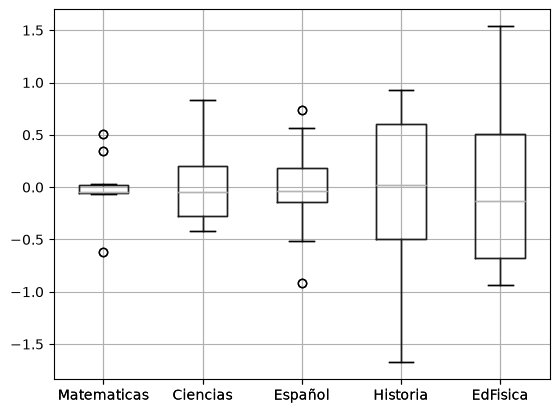

In [22]:
# Error 
Error2 = X - A_reduced2
df_error2 = pd.DataFrame(Error2, columns=df.columns)
df_error2.boxplot()
plt.show()

In [23]:
T2 = U_reduced2.dot(sigma_reduced2)
print('Matrix T (2 dimensions):')
print(T2)

Matrix T (2 dimensions):
[[-17.60868483  -1.60129421]
 [-17.07050248   1.92125519]
 [-18.03227503   1.16003415]
 [-15.23745248  -1.83906523]
 [-16.16352404  -1.63786192]
 [-17.76373552   2.07032438]
 [-16.65588032  -1.3147439 ]
 [-17.49494495   2.54904858]
 [-14.57638852  -1.38822919]
 [-17.36753592  -0.59078306]]


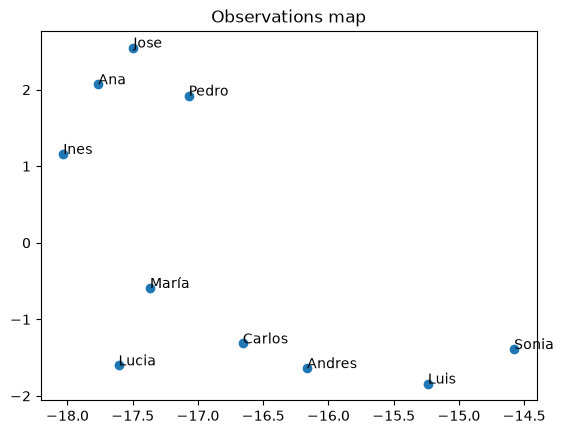

In [24]:
df2 = pd.DataFrame(T2, columns=['a','b'])

xx = df2.a
yy = df2.b

fig, ax = plt.subplots()
ax.set_title('Observations map')
ax.scatter(xx, yy)


for i, txt in enumerate(y):
    ax.annotate(txt, (xx[i], yy[i]))

plt.show()


### Reduccion de la dimensionalidad caso $n = 3$

In [25]:
n_elements = 3

U_reduced3 = U[:, :n_elements]
print('Matrix U_reduced:')
print(U_reduced3)

sigma_reduced3 = Sigma[:n_elements, :n_elements]
print('Matrix sigma reduced:')
print(sigma_reduced3)

VT_reduced3 = VT[:n_elements, :]
print('Matrix VT_reduced')
print(VT_reduced3)

A_reduced3 = U_reduced3.dot(sigma_reduced3.dot(VT_reduced3))
print('Matrix original')
print(A_reduced3)

Matrix U_reduced:
[[-0.33081653 -0.3001899   0.19369375]
 [-0.32070563  0.36017204 -0.23302673]
 [-0.33877457  0.21746818 -0.09613824]
 [-0.28626789 -0.34476413 -0.46044404]
 [-0.30366611 -0.30704514  0.28724434]
 [-0.33372948  0.3881176   0.01487849]
 [-0.31291607 -0.24647116  0.32616313]
 [-0.32867968  0.47786262  0.10049547]
 [-0.2738484  -0.26024723 -0.60546834]
 [-0.32628603 -0.11075236  0.34803114]]
Matrix sigma reduced:
[[53.22794755  0.          0.        ]
 [ 0.          5.33427077  0.        ]
 [ 0.          0.          3.80422605]]
Matrix VT_reduced
[[-4.05461755e-01 -4.57492995e-01 -4.61104128e-01 -4.70897743e-01
  -4.38108690e-01]
 [ 3.04013799e-01  7.08012985e-01 -2.12288727e-01 -2.22197900e-01
  -5.58439623e-01]
 [-6.97436403e-04 -2.64767711e-01  3.14004932e-01  5.93945709e-01
  -6.91756438e-01]]
Matrix original
[[6.65231881 6.72701751 8.69075001 9.08534589 8.09901994]
 [7.50614225 9.40462189 7.18505725 7.08503745 7.0190631 ]
 [7.66431934 9.16779267 7.95365274 8.01637573

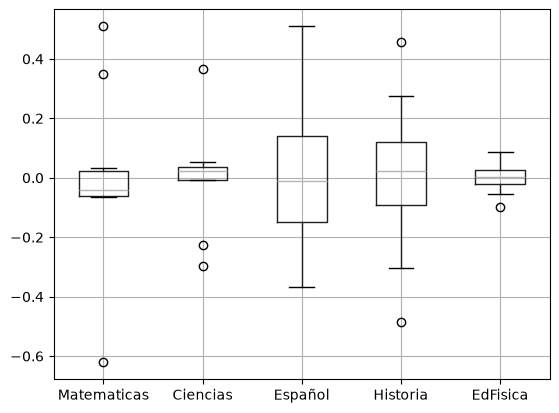

In [26]:
# Error 
Error3 = X - A_reduced3
df_error3 = pd.DataFrame(Error3, columns=df.columns)
df_error3.boxplot()
plt.show()

In [38]:
T3 = U_reduced3.dot(sigma_reduced3)
print('Matrix T (3 dimensions):')
print(T3)

Matrix T (3 dimensions):
[[-17.60868483  -1.60129421   0.7368548 ]
 [-17.07050248   1.92125519  -0.88648635]
 [-18.03227503   1.16003415  -0.36573161]
 [-15.23745248  -1.83906523  -1.75163322]
 [-16.16352404  -1.63786192   1.0927424 ]
 [-17.76373552   2.07032438   0.05660113]
 [-16.65588032  -1.3147439    1.24079827]
 [-17.49494495   2.54904858   0.38230749]
 [-14.57638852  -1.38822919  -2.30333844]
 [-17.36753592  -0.59078306   1.32398914]]


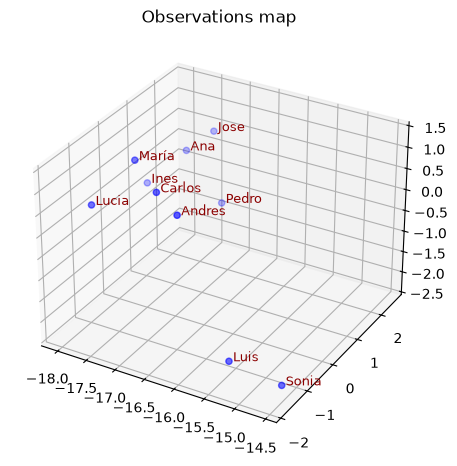

In [53]:
df3 = pd.DataFrame(T3, columns=['a','b', 'c'])

xx = np.array(df3['a'])
yy = np.array(df3['b'])
zz = np.array(df3['c'])

fig = plt.figure()
ax3d = fig.add_subplot(projection='3d')

ax3d.set_title('Observations map')
ax3d.scatter(xx, yy, zz, c='blue',  alpha=0.8)

names = y
for i, (xi, yi, zi) in enumerate(T3):
    ax3d.text(xi, yi, zi, f' {names[i]}', fontsize=9, color='darkred')



plt.tight_layout()

plt.show()


